# Answer RT comparison: accuracy against reading time on the answers

Does the time spent reading the correct answer, or the wrong ones, go with getting the question right? For each trial the figure takes the reading time on the correct answer (A) and the average reading time on the three wrong answers (B, C and D). These are the `RT_normalized_*` columns: the time spent on visits to an answer divided by its number of words, shown in seconds per word. Each of the two measures is cut into 10 equal-width bins over its own range, and each bin shows the share of correct answers with a 95% interval. The data are Study 1's trial table, one row per trial. The times are strongly skewed, so most trials fall in the first bin and the later points rest on few trials; bins with fewer than 5 trials are left out. The intervals treat trials as independent, although each participant contributes many.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "__init__.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.lib.plotting.output import set_output_defaults
set_output_defaults(save=False)   # this notebook only shows; it saves nothing

import matplotlib.pyplot as plt
from src.config import columns as C
from src.config.datasets import dataset
from src.features.build import load_model_ready
from src.analyses.answer_rt_comparison.plots import (
    plot_correctness_by_answer_a_vs_bcd_mean,
    plot_correctness_by_each_answer_rt,
)

trials = load_model_ready()   # one row per trial
print(f"{len(trials):,} trials, {trials[C.PARTICIPANT_ID].nunique()} participants")

19,436 trials, 360 participants


## 1. The input

Per trial: whether the answer was correct (`is_correct`), and the reading time per word on each answer, in milliseconds; the function divides by 1000. An answer nobody looked at has 0.

In [2]:
rt_cols = [f"RT_normalized_answer_{x}" for x in "ABCD"]
trials[[C.PARTICIPANT_ID, C.TRIAL_ID, C.IS_CORRECT_COLUMN, *rt_cols]].head()

,participant_id,TRIAL_INDEX,is_correct,RT_normalized_answer_A,RT_normalized_answer_B,RT_normalized_answer_C,RT_normalized_answer_D
0,l42_2070,4,1,322.125000,213.857143,180.428571,250.714286
1,l42_2070,5,1,113.000000,270.555556,180.000000,131.800000
2,l42_2070,6,1,261.125000,122.000000,201.111111,148.250000
3,l42_2070,7,1,261.400000,172.800000,52.100000,137.000000
4,l42_2070,8,1,104.090909,189.333333,117.875000,67.916667


The spread of the four times. The long right tail, with the maximum far above the 75th percentile, is why most trials land in the first of ten equal-width bins.

In [3]:
trials[rt_cols].describe().round(1)

,RT_normalized_answer_A,RT_normalized_answer_B,RT_normalized_answer_C,RT_normalized_answer_D
count,19436.0,19436.0,19436.0,19436.0
mean,355.2,245.0,209.8,207.6
std,330.4,267.4,232.1,219.1
min,0.0,0.0,0.0,0.0
25%,179.7,114.2,98.9,102.2
50%,264.5,174.3,147.2,149.3
75%,408.0,286.7,241.1,237.7
max,5540.0,7694.0,9610.5,7997.0


## 2. All participants

One curve for the time on the correct answer and one for the mean time on the wrong answers (see the legend). The table has one row per curve and bin: the bin's edges and centre in seconds per word, the number of trials, how many were correct, the accuracy and its interval. Read `n` before reading a point.

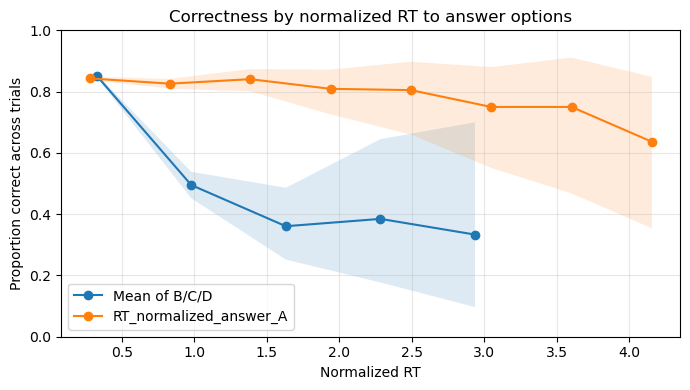

,metric,bin_left,bin_right,bin_center,n,k_correct,accuracy,ci_low,ci_high
0,RT_normalized_answer_A,0.000,0.554,0.277,16694,14075,0.843,0.838,0.849
1,RT_normalized_answer_A,0.554,1.108,0.831,2149,1775,0.826,0.809,0.841
2,RT_normalized_answer_A,1.108,1.662,1.385,389,327,0.841,0.801,0.874
3,RT_normalized_answer_A,1.662,2.216,1.939,110,89,0.809,0.726,0.872
4,RT_normalized_answer_A,2.216,2.770,2.493,41,33,0.805,0.660,0.898
5,RT_normalized_answer_A,2.770,3.324,3.047,24,18,0.750,0.551,0.880
6,RT_normalized_answer_A,3.324,3.878,3.601,12,9,0.750,0.468,0.911
7,RT_normalized_answer_A,3.878,4.432,4.155,11,7,0.636,0.354,0.848
8,Mean of B/C/D,0.000,0.652,0.326,18843,16057,0.852,0.847,0.857
9,Mean of B/C/D,0.652,1.305,0.978,511,253,0.495,0.452,0.538


In [4]:
fig, table = plot_correctness_by_answer_a_vs_bcd_mean(trials, save=False)
plt.show()
table.round(3)

### Each answer separately

The same question with the three wrong answers kept apart: one curve per answer, A (correct) in green, then B, C and D. Here all four curves share one set of 10 equal-width bins, cut over the range of all four times together, so a bin means the same time on every curve. Because those bins span the longest time on any answer, even more trials fall in the first bin than in the figure above.

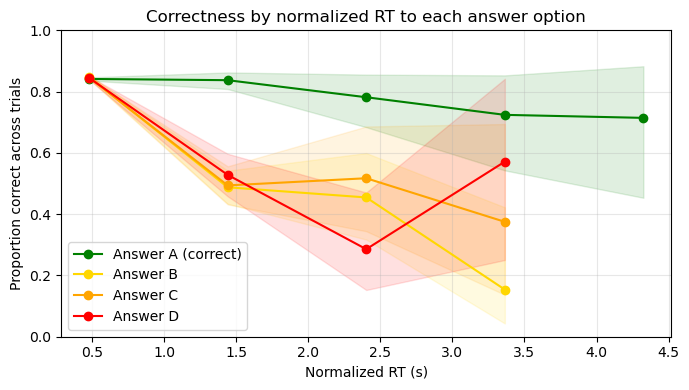

,metric,bin_left,bin_right,bin_center,n,k_correct,accuracy,ci_low,ci_high
0,Answer A (correct),0.000,0.961,0.481,18590,15640,0.841,0.836,0.846
1,Answer A (correct),0.961,1.922,1.442,713,597,0.837,0.808,0.863
2,Answer A (correct),1.922,2.883,2.403,87,68,0.782,0.684,0.855
3,Answer A (correct),2.883,3.844,3.364,29,21,0.724,0.543,0.853
4,Answer A (correct),3.844,4.805,4.325,14,10,0.714,0.454,0.883
5,Answer B,0.000,0.961,0.481,19046,16155,0.848,0.843,0.853
6,Answer B,0.961,1.922,1.442,326,159,0.488,0.434,0.542
7,Answer B,1.922,2.883,2.403,44,20,0.455,0.317,0.599
8,Answer B,2.883,3.844,3.364,13,2,0.154,0.043,0.422
9,Answer C,0.000,0.961,0.481,19151,16199,0.846,0.841,0.851


In [5]:
fig, table_each = plot_correctness_by_each_answer_rt(trials, save=False)
plt.show()
table_each.round(3)

## 3. Hunters and gatherers

Each function draws whatever trials it is given, so a group is shown by passing that group's trial table; `group=` only labels the saved file name. Each call bins over the range of its own data, so the bin edges differ between the two groups. Hunters saw the question before reading the text; gatherers read the text first.

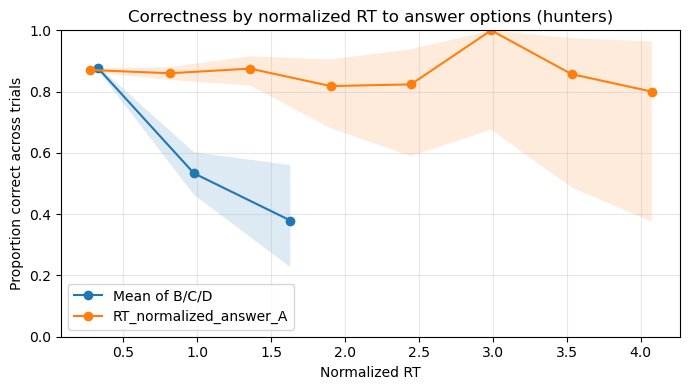

,metric,bin_left,bin_right,n,accuracy
0,RT_normalized_answer_A,0.000,0.544,8387,0.871
1,RT_normalized_answer_A,0.544,1.087,1064,0.860
2,RT_normalized_answer_A,1.087,1.631,184,0.875
3,RT_normalized_answer_A,1.631,2.174,44,0.818
4,RT_normalized_answer_A,2.174,2.718,17,0.824
5,RT_normalized_answer_A,2.718,3.262,8,1.000
6,RT_normalized_answer_A,3.262,3.805,7,0.857
7,RT_normalized_answer_A,3.805,4.349,5,0.800
8,Mean of B/C/D,0.000,0.652,9488,0.878
9,Mean of B/C/D,0.652,1.305,195,0.533


In [6]:
hunters = load_model_ready(dataset("l1").model_ready_split("hunters"))
fig, table_hunters = plot_correctness_by_answer_a_vs_bcd_mean(
    hunters, title="Correctness by normalized RT to answer options (hunters)",
    save=False, group="hunters",
)
plt.show()
table_hunters[["metric", "bin_left", "bin_right", "n", "accuracy"]].round(3)

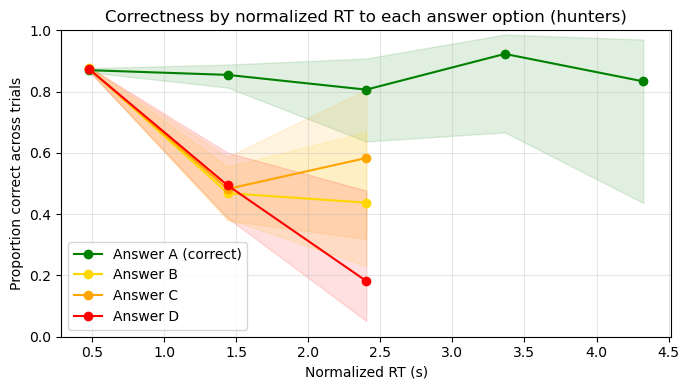

,metric,bin_left,bin_right,n,accuracy
0,Answer A (correct),0.000,0.961,9330,0.870
1,Answer A (correct),0.961,1.922,337,0.855
2,Answer A (correct),1.922,2.883,31,0.806
3,Answer A (correct),2.883,3.844,13,0.923
4,Answer A (correct),3.844,4.805,6,0.833
5,Answer B,0.000,0.961,9568,0.876
6,Answer B,0.961,1.922,128,0.469
7,Answer B,1.922,2.883,16,0.438
8,Answer C,0.000,0.961,9617,0.873
9,Answer C,0.961,1.922,85,0.482


In [7]:
fig, table_each_hunters = plot_correctness_by_each_answer_rt(
    hunters, title="Correctness by normalized RT to each answer option (hunters)",
    save=False, group="hunters",
)
plt.show()
table_each_hunters[["metric", "bin_left", "bin_right", "n", "accuracy"]].round(3)

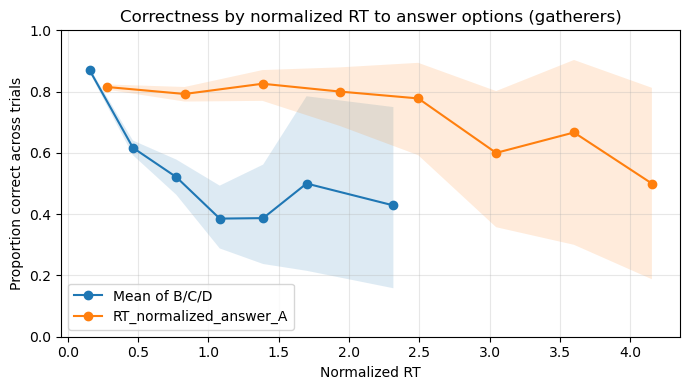

,metric,bin_left,bin_right,n,accuracy
0,RT_normalized_answer_A,0.000,0.554,8260,0.815
1,RT_normalized_answer_A,0.554,1.108,1117,0.792
2,RT_normalized_answer_A,1.108,1.662,218,0.826
3,RT_normalized_answer_A,1.662,2.216,65,0.800
4,RT_normalized_answer_A,2.216,2.770,27,0.778
5,RT_normalized_answer_A,2.770,3.324,15,0.600
6,RT_normalized_answer_A,3.324,3.878,6,0.667
7,RT_normalized_answer_A,3.878,4.432,6,0.500
8,Mean of B/C/D,0.000,0.309,7705,0.871
9,Mean of B/C/D,0.309,0.618,1589,0.617


In [8]:
gatherers = load_model_ready(dataset("l1").model_ready_split("gatherers"))
fig, table_gatherers = plot_correctness_by_answer_a_vs_bcd_mean(
    gatherers, title="Correctness by normalized RT to answer options (gatherers)",
    save=False, group="gatherers",
)
plt.show()
table_gatherers[["metric", "bin_left", "bin_right", "n", "accuracy"]].round(3)

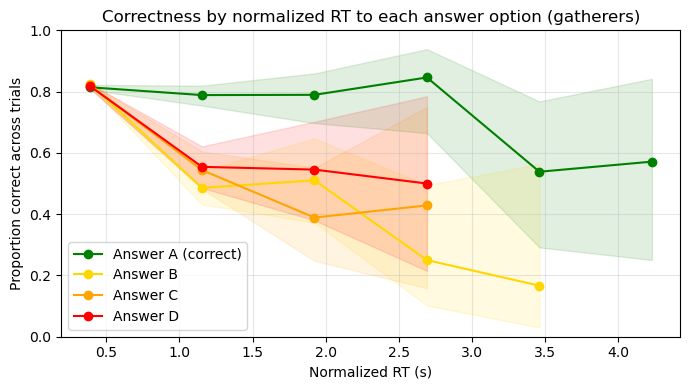

,metric,bin_left,bin_right,n,accuracy
0,Answer A (correct),0.000,0.769,8973,0.814
1,Answer A (correct),0.769,1.539,601,0.789
2,Answer A (correct),1.539,2.308,95,0.789
3,Answer A (correct),2.308,3.078,26,0.846
4,Answer A (correct),3.078,3.847,13,0.538
5,Answer A (correct),3.847,4.616,7,0.571
6,Answer B,0.000,0.769,9325,0.826
7,Answer B,0.769,1.539,319,0.486
8,Answer B,1.539,2.308,47,0.511
9,Answer B,2.308,3.078,16,0.250


In [9]:
fig, table_each_gatherers = plot_correctness_by_each_answer_rt(
    gatherers, title="Correctness by normalized RT to each answer option (gatherers)",
    save=False, group="gatherers",
)
plt.show()
table_each_gatherers[["metric", "bin_left", "bin_right", "n", "accuracy"]].round(3)

Other settings: `n_bins` (number of bins), `min_n_per_bin` (the smallest bin kept), `show_ci`, `rt_divisor`, and the text arguments `title`, `x_label` and `y_label`. Both functions take the same settings; the per-answer one also takes `answer_cols`, the label and column of each curve. This analysis has no runner; a driver calls the functions directly with `save=True` to write the figure and its table under `reports/answer_rt_comparison/`.